# Round 2 of policy iteration: one context-dependent deviation from the UCB schedule

## Description

<!-- Written 2026-11-12 15:45 before the first run (pre-registration). Follows notebook 13 (option_policy, INCONCLUSIVE) and Tim's mandate of 2026-11-12 ("do both": predict EI's failure, and repeated decisions). Issue #13. -->

**Question.** Round 1 (notebook 13) improved on EI with one deviation, but the improvement was static: "switch to UCB(0.995) early" (+0.119 [0.074, 0.165] log10 over EI); reading the context added +0.017 [−0.018, 0.050]. **If that static improvement is accepted as the new base policy π₁ = UCB, does a second, context-dependent decision improve on it, beyond what a context-free schedule from the same options gives?** The run then has repeated decisions: EI → UCB (round 1, every task), then UCB → another option at a time and to an arm chosen from the context (round 2).

Why this could work where round 1 did not (post hoc on the pilot of notebook 13, run artifact `labels.pt` of `pilot_20261112-123724`; exploratory, the reason for this design and not a result):
- UCB instead of EI helps a lot on the third of tasks where EI ends badly (+0.68 for "UCB for the rest" from t = 2) and hurts on the other two thirds (−0.18, −0.11).
- Round 1 must decide early, when it is hard to tell which kind of task it is: EI's terminal regret is predicted from the context with Spearman 0.45 at t = 2 and 0.62 at t = 6. Missing a hard task costs four times what a false alarm costs, so the best gate is "always deviate".
- Round 2 asks an easier question, later: now that UCB has run for t steps, is this a run where polishing with EI (or PI, or the mean) pays? That is about the present state, which the belief features describe (distance of the picks to the incumbent, local uncertainty, expected improvement left).

**Setup.** The pipeline of notebook 13 unchanged (`tasks/option_policy.py`, `experimental/option_policy.py`, `analysis/option_policy.py`), with:
- **base policy π₁ = UCB(0.995)** for the whole run (prefix under seed 0);
- **options** at t ∈ {0, 2, …, 14}: each of EI, PI(0.01), MES, mean for 3 steps and then UCB to T, or for the rest of the run (8 options, 2 candidate-set seeds, exact outcomes);
- **portfolios**: `nomes` (**primary**): EI, PI, mean; `all`: plus MES;
- **tasks**: 4000 fresh prior draws, split 4, task offset 40000 (notebook 13 used 30000–31999). d = 2, n_init = 4, T = 20, pfn_large, fp32, noise-free. Twice the tasks of notebook 13, whose CI on the context part (±0.035) was too wide for the worthwhile 0.022;
- everything else as in notebook 13: reward = terminal log10 regret with ε = 1e-6; feature sets `time`, `data`, `belief`, `pfn`; MLP (and ridge on `belief`); one-deviation rule with conservative threshold (c = ∞, never deviate, is allowed and wins ties); 5-fold cross-fitting over tasks with inner folds for c; comparators: the base (UCB), the best static schedule from UCB, the shuffled null, the `time` policy, the privileged oracle.
- **EI on the same tasks**: the option "EI for the rest" at t = 0 is the full EI run under each seed. So UCB vs EI, and the round-2 policy vs EI, are measured on these tasks (table `per_task`, columns `full:*`).

**What to look for.**
1. **Primary:** `nomes/belief/mlp`, seed 0: gain over UCB; **gain over the best static schedule from UCB** (the context-dependent part); gain over its shuffled null.
2. Does round 1 replicate on fresh tasks: UCB vs EI (expected about +0.12).
3. The total: round-2 policy vs EI, and vs the best static two-decision schedule (UCB, then the static schedule).
4. Secondary, as in notebook 13: seed 1; the `all` portfolio; feature sets (`belief` vs `data` is PFN-reading vs D-only); oracle headroom and the share captured; which steps and options are chosen; fit of Q against the labels' cross-seed correlation; ε = 1e-5.

**GO / NO-GO** (rule `analysis/option_policy.py::policy_verdict` on `nomes/belief/mlp`, seed 0; worthwhile = 0.022 log10, i.e. 5% less regret; the same rule as notebook 13 with UCB as the base).
- **GO**: the gain over UCB has CI > 0, and the gain over the static schedule has CI > 0 and is ≥ 0.022. A second, context-reading decision adds to the static improvement. Next: iterate (round 3 from the learned policy, closed loop), then d = 4.
- **NO-GO**: the upper CI bound of the gain over the static schedule is < 0.022. With these readouts the context does not time or choose the second decision either. Next: stop refining option policies on these features at d = 2; move to d = 4 or to other readouts.
- **INCONCLUSIVE**: otherwise.

A gain over UCB that a static schedule also gives (e.g. "UCB until t = 10, then EI") is *not* a GO; it is a better schedule, reported as such.

**Limits.**
- As notebook 13: noise-free P0, d = 2, T = 20; offline-exact for seed 0 (every decision state is a UCB-prefix state); one deviation from π₁ per run, at even steps.
- π₁ is pure UCB from t = 0. Round 1's static choice was "UCB from t = 2 or 4" (+0.131, +0.113 against +0.121 from t = 0 in notebook 13: not distinguishable).
- UCB as π₁ was chosen on notebook 13's tasks; these tasks are fresh, so UCB vs EI here is a replication.
- The exploratory reasons above come from notebook 13's pilot tasks, not from these.
- Labels carry GPU floating-point noise at the scale of ε (notebook 13, note after the sanity run).


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from anytime_acq.analysis import load_snapshot, show_header
from anytime_acq.analysis.option_policy import policy_verdict
from anytime_acq.analysis.stats import bootstrap_ci

SNAPSHOT = "results/option_policy_r2/pilot_20261113-090450"  # set after `just snapshot`
snap = load_snapshot(SNAPSHOT)
show_header(snap)  # how it was run + configuration, generated from the snapshot

## How it was run

```bash
just sweep detached pilot experiment=option_policy_r2
```

|  |  |
|---|---|
| stage | pilot |
| sweep | `pilot_20261113-090450` |
| commit | `daaa02374c18` (tag `sweep/option_policy_r2/pilot_20261113-090450`) |
| backend / host | detached / ulysses |
| ran | 2026-11-13T09:04:52 → 2026-11-13T15:52:02 |
| members | 1: 1 done |
| compute | 6.8 h wall, 0.0 min GPU |

## Configuration

Experiment config (`configs/experiment/option_policy_r2.yaml`):

```yaml
# @package _global_
# Round 2 of policy iteration: one context-dependent deviation from the UCB schedule (issue #13).
# The pipeline of option_policy with base = UCB(0.995), the static improvement found in round 1 (notebook 13).
# Pre-registration: notebooks/14_2026-11-12_option_policy_r2.ipynb.
defaults:
  - override /task: option_policy

task:
  d: 2
  base: ucb0.995
  tasks: {split: 4, task_offset: 40000, n_tasks: 4000}
  portfolios:
    nomes: [ei, pi0.01, mean]
    all: [ei, pi0.01, mes, mean]
```

**Varying:** nothing

**Replicates:** none

**Constant:**

```yaml
seed: 0
task:
  T_per_d: 10
  arms: '["ei", "pi0.01", "ucb0.995", "mes", "mean"]'
  base: ucb0.995
  candidates.local_sigmas: '[0.01, 0.05, 0.2]'
  candidates.n_local: 64
  candidates.n_sobol: 1024
  chunk: 256
  d: 2
  device: cuda
  eps: 1.0e-06
  feature_sets: '["time", "data", "belief", "pfn"]'
  fit.batch: 1024
  fit.dropout: 0.1
  fit.epochs: 150
  fit.lr: 0.002
  fit.n_ens: 2
  fit.patience: 15
  fit.weight_decay: 0.001
  fit.width: 128
  ks: '[3]'
  n_boot: 2000
  n_folds: 5
  n_init_per_d: 2
  n_inner: 4
  name: option_policy
  pfn: pfn_large
  portfolios.all: '["ei", "pi0.01", "mes", "mean"]'
  portfolios.nomes: '["ei", "pi0.01", "mean"]'
  primary: nomes/belief/mlp
  rest: true
  seeds: '[0, 1]'
  steps: '[0, 2, 4, 6, 8, 10, 12, 14]'
  task_chunk: 500
  task_draw.n_dense: 16384
  task_draw.n_refine: 16
  task_draw.refine_steps: 200
  tasks.n_tasks: 4000
  tasks.split: 4
  tasks.task_offset: 40000
  tf32: false
  worthwhile_log10: 0.022
  z_pca: 32
```

In [ ]:
runs = snap.runs
print("member status:", runs.status.value_counts().to_dict())
print("minutes:", {k: round(float(runs.iloc[0][k]) / 60, 1) for k in runs.columns if k.startswith("time/")})
summ, per, usage, fit, opts = (snap.table(k) for k in ("summary", "per_task", "usage", "fit", "options"))
PRIMARY, WORTH = "nomes/belief/mlp", 0.022
print("held-out tasks:", len(per), "| folds:", per.fold.nunique())

member status: {'DONE': 1}
minutes: {'time/collect_s': 405.2, 'time/evaluate_s': 1.9}
held-out tasks: 4000 | folds: 5


## 1. The primary policy: gain over UCB, over the static schedule from UCB, over its shuffled null

In [ ]:
def show(variants, seed=0):
    s = summ[summ.variant.isin(variants) & (summ.seed == seed)]
    t = s.assign(ci=[f"{m:+.3f} [{lo:+.3f}, {hi:+.3f}]" for m, lo, hi in zip(s["mean"], s.lo, s.hi)])
    out = t.pivot(index="variant", columns="contrast", values="ci").reindex(variants)
    out["deviates"] = s.groupby("variant").deviates.first().reindex(variants).round(2)
    return out[[c for c in ("vs_base", "vs_static", "vs_shuffled", "deviates") if c in out]]

print("log10 terminal regret, positive = better; paired over held-out tasks, 95% bootstrap CI")
print("seed 0 (the deployed policy; exact gain over the UCB run):")
display(show([PRIMARY, "nomes/static"], 0))
print("seed 1 (the decision executed on a different candidate set):")
display(show([PRIMARY, "nomes/static"], 1))
o = summ[summ.variant == "nomes/oracle"].iloc[0]
g = summ[(summ.variant == PRIMARY) & (summ.seed == 0) & (summ.contrast == "vs_base")].iloc[0]
print(f"privileged one-deviation headroom (cross-fitted over seeds): {o['mean']:.3f} [{o.lo:.3f}, {o.hi:.3f}];"
      f" share captured by the policy: {g['mean'] / o['mean']:.0%}")

log10 terminal regret, positive = better; paired over held-out tasks, 95% bootstrap CI
seed 0 (the deployed policy; exact gain over the UCB run):


contrast,vs_base,vs_static,vs_shuffled,deviates
variant,,,,
nomes/belief/mlp,"+0.090 [+0.072, +0.110]","-0.023 [-0.043, -0.003]","+0.087 [+0.072, +0.103]",0.28
nomes/static,"+0.113 [+0.095, +0.134]",NaN,NaN,NaN


seed 1 (the decision executed on a different candidate set):


contrast,vs_base,vs_static,vs_shuffled,deviates
variant,,,,
nomes/belief/mlp,"+0.092 [+0.073, +0.112]","-0.017 [-0.040, +0.005]","+0.091 [+0.074, +0.108]",0.28
nomes/static,"+0.109 [+0.090, +0.130]",NaN,NaN,NaN


privileged one-deviation headroom (cross-fitted over seeds): 0.255 [0.232, 0.278]; share captured by the policy: 35%


## 2. Feature sets, learners and portfolios

contrast,vs_base,vs_static,vs_shuffled,deviates
variant,,,,
nomes/time/mlp,"+0.062 [+0.043, +0.083]","-0.051 [-0.068, -0.036]","+0.000 [+0.000, +0.000]",0.80
nomes/data/mlp,"+0.077 [+0.058, +0.096]","-0.037 [-0.055, -0.018]","+0.068 [+0.053, +0.084]",0.28
nomes/belief/mlp,"+0.090 [+0.072, +0.110]","-0.023 [-0.043, -0.003]","+0.087 [+0.072, +0.103]",0.28
nomes/pfn/mlp,"+0.084 [+0.064, +0.104]","-0.030 [-0.050, -0.010]","+0.087 [+0.071, +0.104]",0.28
nomes/belief/ridge,"+0.072 [+0.052, +0.092]","-0.042 [-0.061, -0.021]","+0.103 [+0.088, +0.121]",0.50
nomes/static,"+0.113 [+0.095, +0.134]",NaN,NaN,NaN
all/time/mlp,"+0.062 [+0.043, +0.082]","-0.052 [-0.069, -0.036]","+0.000 [+0.000, +0.000]",0.80
all/data/mlp,"+0.087 [+0.068, +0.106]","-0.026 [-0.045, -0.007]","+0.074 [+0.058, +0.090]",0.33
all/belief/mlp,"+0.100 [+0.080, +0.121]","-0.013 [-0.033, +0.006]","+0.095 [+0.078, +0.112]",0.33


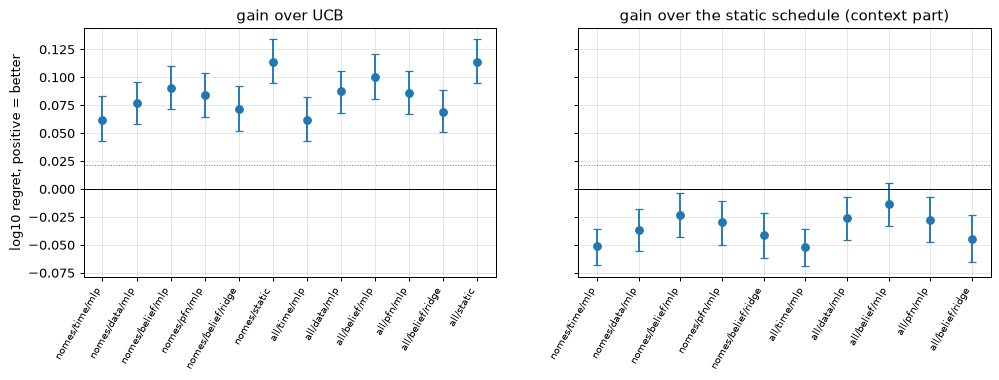

In [ ]:
order = [f"{pf}/{fs}/mlp" for pf in ("nomes", "all") for fs in ("time", "data", "belief", "pfn")]
order = order[:4] + ["nomes/belief/ridge", "nomes/static"] + order[4:] + ["all/belief/ridge", "all/static"]
display(show(order, 0))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), dpi=90, sharey=True)
for a, contrast in zip(ax, ("vs_base", "vs_static")):
    s = summ[(summ.seed == 0) & (summ.contrast == contrast) & summ.variant.isin(order)].set_index("variant").reindex(order).dropna(subset=["mean"])
    a.errorbar(range(len(s)), s["mean"], yerr=[s["mean"] - s.lo, s.hi - s["mean"]], fmt="o", capsize=3)
    a.axhline(0, color="k", lw=.8); a.axhline(WORTH, color="gray", ls=":", lw=.8)
    a.set_xticks(range(len(s))); a.set_xticklabels(s.index, rotation=60, ha="right", fontsize=8)
    a.set_title({"vs_base": "gain over UCB", "vs_static": "gain over the static schedule (context part)"}[contrast]); a.grid(alpha=.3)
ax[0].set_ylabel("log10 regret, positive = better"); plt.show()

## 3. What the policy does: steps, options, thresholds

In [ ]:
u = usage[usage.variant.isin([PRIMARY, "all/belief/mlp"])]
for v, g in u.groupby("variant"):
    print(v, "(tasks per decision; step -1 = never deviates)")
    display(g.pivot_table(index="option", columns="step", values="n", aggfunc="sum", fill_value=0))
print("static schedule chosen per fold:"); display(usage[usage.variant.str.endswith("/static")][["variant", "fold", "step", "option"]])
print("thresholds c per fold (primary):", sorted(per.groupby("fold")[f"{PRIMARY}:c"].first().round(3).tolist()))
print("mean advantage per decision step and option (seed 0):")
display(opts.pivot(index="option", columns="step", values="adv0").round(3))

all/belief/mlp (tasks per decision; step -1 = never deviates)


step,-1,0,2,4,6,8,10,12,14
option,,,,,,,,,
base,2668,0,0,0,0,0,0,0,0
ei_k3,0,0,0,0,0,1,0,0,0
ei_rest,0,19,84,192,215,146,71,50,41
mean_k3,0,0,0,1,1,0,0,0,0
mean_rest,0,0,0,0,0,0,0,1,5
mes_rest,0,0,12,95,136,108,73,34,28
pi0.01_rest,0,0,0,0,3,0,3,6,7


nomes/belief/mlp (tasks per decision; step -1 = never deviates)


step,-1,0,2,4,6,8,10,12,14
option,,,,,,,,,
base,2894,0,0,0,0,0,0,0,0
ei_k3,0,0,0,0,1,9,4,3,1
ei_rest,0,6,59,184,242,217,144,104,82
mean_k3,0,0,0,0,0,3,2,2,0
mean_rest,0,0,0,0,0,1,4,13,8
pi0.01_rest,0,0,0,0,2,2,3,4,6


static schedule chosen per fold:


,variant,fold,step,option
0,nomes/static,0,7,ei_rest
1,nomes/static,1,7,ei_rest
2,nomes/static,2,7,ei_rest
3,nomes/static,3,7,ei_rest
4,nomes/static,4,7,ei_rest
5,all/static,0,7,ei_rest
6,all/static,1,7,ei_rest
7,all/static,2,7,ei_rest
8,all/static,3,7,ei_rest
9,all/static,4,7,ei_rest


thresholds c per fold (primary): [0.172, 0.199, 0.233, 0.271, 0.337]
mean advantage per decision step and option (seed 0):


step,0,2,4,6,8,10,12,14
option,,,,,,,,
ei_k3,0.021,-0.002,-0.012,0.011,0.017,0.028,0.042,0.071
ei_rest,-0.082,-0.060,-0.067,-0.013,0.036,0.051,0.098,0.113
mean_k3,-0.073,-0.088,-0.076,-0.064,-0.043,-0.035,0.006,0.046
mean_rest,-1.047,-0.793,-0.549,-0.374,-0.238,-0.132,-0.038,0.030
mes_k3,0.016,0.019,0.025,0.002,0.007,0.015,0.016,0.029
mes_rest,0.039,0.047,0.069,0.067,0.071,0.078,0.079,0.086
pi0.01_k3,-0.016,-0.014,0.006,0.008,0.017,0.019,0.021,0.030
pi0.01_rest,-0.622,-0.606,-0.555,-0.478,-0.361,-0.278,-0.195,-0.106


## 4. How well Q is fitted, against the labels' noise ceiling

In [ ]:
f = fit.pivot_table(index="option", columns=["features", "learner"], values="spearman").round(3)
f["label seed corr"] = fit.groupby("option").seed_corr.first().round(3)
print("held-out Spearman of Q with the seed-mean advantage, per option; last column: correlation of the label across the two seeds")
display(f)
display(fit.groupby(["features", "learner"])[["spearman", "r2"]].mean().round(3))

held-out Spearman of Q with the seed-mean advantage, per option; last column: correlation of the label across the two seeds


features    belief          data    pfn   time label seed corr
learner        mlp  ridge    mlp    mlp    mlp                
option                                                        
ei_k3        0.064  0.059  0.050  0.060  0.035           0.316
ei_rest      0.197  0.186  0.143  0.191  0.072           0.586
mean_k3      0.111  0.098  0.094  0.106  0.073           0.376
mean_rest    0.337  0.323  0.315  0.334  0.288           0.783
mes_k3       0.013  0.009  0.019  0.015  0.010           0.156
mes_rest     0.175  0.173  0.152  0.170  0.011           0.302
pi0.01_k3    0.033  0.036  0.024  0.027  0.018           0.271
pi0.01_rest  0.425  0.387  0.364  0.427  0.176           0.674

spearman     r2
features learner                 
belief   mlp         0.169  0.057
         ridge       0.159  0.045
data     mlp         0.145  0.040
pfn      mlp         0.166  0.054
time     mlp         0.085  0.020

## 4b. Against EI on the same tasks: round 1 (UCB), the static two-decision schedule, the round-2 policy

In [ ]:
EPS = 1e-6
lg = lambda x: np.log10(np.asarray(x, dtype=float) + EPS)
rows = []
def add(name, x):
    lo, hi = bootstrap_ci(np.asarray(x), n_boot=2000)
    rows.append({"contrast": name, "mean": np.mean(x), "lo": lo, "hi": hi})
for s in (0, 1):
    ei, ucb = lg(per[f"full:ei_rest{s}"]), lg(per[f"full:base{s}"])
    add(f"seed {s}: UCB (round 1) over EI", ei - ucb)
    for arm in ("mes", "pi0.01", "mean"):
        add(f"seed {s}: static {arm} over EI", ei - lg(per[f"full:{arm}_rest{s}"]))
    for v in (PRIMARY, "all/belief/mlp"):
        add(f"seed {s}: UCB + static schedule [{v.split('/')[0]}] over EI", ei - ucb + per[f"{v}:static{s}"])
        add(f"seed {s}: round-2 policy {v} over EI", ei - ucb + per[f"{v}:v{s}"])
print("log10 terminal regret of full runs, positive = better than EI; paired over tasks, 95% bootstrap CI")
display(pd.DataFrame(rows).set_index("contrast").round(3))

log10 terminal regret of full runs, positive = better than EI; paired over tasks, 95% bootstrap CI


,mean,lo,hi
contrast,,,
seed 0: UCB (round 1) over EI,0.082,0.046,0.114
seed 0: static mes over EI,0.121,0.090,0.153
seed 0: static pi0.01 over EI,-0.541,-0.582,-0.501
seed 0: static mean over EI,-0.965,-1.014,-0.916
seed 0: UCB + static schedule [nomes] over EI,0.195,0.164,0.226
seed 0: round-2 policy nomes/belief/mlp over EI,0.172,0.140,0.203
seed 0: UCB + static schedule [all] over EI,0.195,0.164,0.226
seed 0: round-2 policy all/belief/mlp over EI,0.182,0.149,0.213
seed 1: UCB (round 1) over EI,0.090,0.057,0.125


## 5. Robustness: ε = 1e-5, and the numerical noise of the labels

In [ ]:
def gain_eps(v, eps, s=0):
    return np.log10(per[f"{v}:regret_base{s}"] + eps) - np.log10(per[f"{v}:regret{s}"] + eps)

rows = []
for v in (PRIMARY, "all/belief/mlp", "nomes/pfn/mlp", "nomes/data/mlp"):
    for eps in (1e-6, 1e-5):
        x = gain_eps(v, eps).to_numpy()
        lo, hi = bootstrap_ci(x, n_boot=2000)
        rows.append({"variant": v, "eps": eps, "gain over UCB": x.mean(), "lo": lo, "hi": hi})
print("the same decisions, scored at another eps (the policy itself was trained at eps = 1e-6):")
display(pd.DataFrame(rows).round(3))

the same decisions, scored at another eps (the policy itself was trained at eps = 1e-6):


,variant,eps,gain over UCB,lo,hi
0,nomes/belief/mlp,0.0,0.090,0.072,0.110
1,nomes/belief/mlp,0.0,0.078,0.062,0.096
2,all/belief/mlp,0.0,0.100,0.080,0.121
3,all/belief/mlp,0.0,0.085,0.069,0.104
4,nomes/pfn/mlp,0.0,0.084,0.064,0.104
5,nomes/pfn/mlp,0.0,0.071,0.054,0.088
6,nomes/data/mlp,0.0,0.077,0.058,0.096
7,nomes/data/mlp,0.0,0.066,0.050,0.081


## Observations (2026-11-14)

Snapshot `results/option_policy_r2/pilot_20261113-090450` (4000 tasks, 1 member, DONE). log10 terminal regret at ε = 1e-6, positive = better, held-out tasks, 95% bootstrap CI; `summary` table and the cell outputs above.

1. **The round-2 policy does not beat the static schedule from UCB; it is worse.** `nomes/belief/mlp` over static: −0.023 [−0.043, −0.003] (seed 1: −0.017 [−0.040, 0.005]). No variant is above static; the best, `all/belief/mlp`, is −0.013 [−0.033, 0.006].
2. **The static schedule is the result.** "UCB(0.995), then EI for the rest from the last decision step" gains +0.113 [0.095, 0.134] over UCB and **+0.195 [0.164, 0.226] over EI** (seed 1: +0.200 [0.165, 0.235]); static MES is +0.121 [0.090, 0.153] over EI and UCB alone +0.082 [0.046, 0.114] (section 4b). Explore with UCB, exploit with EI at the end: 36% less regret than EI.
3. **The context is used and still loses.** The policy is +0.087 [0.072, 0.103] over its shuffled null and +0.090 [0.072, 0.110] over UCB, deviating in 28% of the tasks. It switches to EI too early: the mean advantage of "EI for the rest" is negative until t = 6 and largest at the last step (section 3).
4. **Q is still poorly fitted.** Held-out R² 0.057 (belief, MLP), Spearman 0.17; data features 0.040, time only 0.020 (section 4).
5. **Privileged one-deviation headroom from UCB: 0.255 [0.232, 0.278]**, of which the policy captures 35% and the static schedule 44%.

Limits: one deviation per run; d = 2; ε = 1e-6 (at 1e-5 the policy's gain over UCB is 0.078 instead of 0.090, section 5).


## Verdict

**NO-GO** by the pre-registered rule on `nomes/belief/mlp`, seed 0: policy over the static schedule −0.023 [−0.043, −0.003] (upper bound below 0.022). Record with `just decide`.


In [ ]:
print("pre-registered rule on", PRIMARY, "seed 0:", policy_verdict(summ, PRIMARY, WORTH))

pre-registered rule on nomes/belief/mlp seed 0: NO-GO
